# 04b — Calcul économique et sensibilité aux hypothèses (train uniquement)
**Auteure : Maïlys Augier**

Ce notebook traduit en euros les résultats de `04_modeles` (Ihmane) et teste la solidité du gain si les hypothèses de la direction sont fausses.
- Il lit `resultats/04_comparaison_cv.csv` : **exécuter `04_modeles` d'abord**.
- Les règles simples et le ciblage au hasard sont recalculés avec les mêmes fonctions et les mêmes 5 plis (`modele_utils`).
- Le fichier test n'est pas utilisé.

In [1]:
import sys
from pathlib import Path

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
import modele_utils as mu

FIGURES = RACINE / "figures"
RESULTATS = RACINE / "resultats"
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Gain d'une approche et seuil de rentabilité

Hypothèses de la direction : un insatisfait sur trois ne revient pas (600 € perdus), une approche en ramène la moitié, une approche coûte 40 €.

In [2]:
PERTE_CLIENT, P_DEPART, P_RECUP = 600, 1 / 3, 1 / 2
valeur = PERTE_CLIENT * P_DEPART * P_RECUP
assert round(valeur) == config.GAIN_VRAI_INSATISFAIT  # cohérent avec config.py
print(f"Perte évitée par vrai insatisfait approché : {valeur:.0f} €")
print(f"Gain net : {mu.GAIN_BON_CHOIX:+.0f} € (vrai insatisfait) / {mu.GAIN_MAUVAIS_CHOIX:+.0f} € (passager satisfait)")
print(f"Seuil de rentabilité : précision ≥ {config.COUT_APPROCHE / config.GAIN_VRAI_INSATISFAIT:.0%}")

Perte évitée par vrai insatisfait approché : 100 €
Gain net : +60 € (vrai insatisfait) / -40 € (passager satisfait)
Seuil de rentabilité : précision ≥ 40%


## 2. Toutes les méthodes, en euros (validation croisée, 5 plis)

In [3]:
df, y = mu.charger_train()
decoupage = mu.plis(y)
print(f"Passagers neutres ou insatisfaits : {y.mean():.1%}")

lignes = {f"Règle « {nom} »": mu.cv(y, regle(df).to_numpy(), decoupage).mean()
          for nom, regle in mu.REGLES.items()}
lignes["Au hasard"] = mu.cv(y, np.zeros(len(y)), decoupage).mean()  # tous ex aequo = tirage au hasard
methodes = pd.DataFrame(lignes).T[["Précision top 10 %", "Gain / 1000 passagers (€)"]]

modeles = pd.read_csv(RESULTATS / "04_comparaison_cv.csv", index_col=0)
for nom in ["Arbre de décision", "Régression logistique", "Modèle parfait (borne)"]:
    methodes.loc[nom] = modeles.loc[nom, ["Précision top 10 %", "Gain / 1000 passagers (€)"]].values
methodes = methodes.sort_values("Gain / 1000 passagers (€)", ascending=False)
methodes.to_csv(RESULTATS / "04b_gain_par_methode.csv")
methodes

Passagers neutres ou insatisfaits : 56.7%


,Précision top 10 %,Gain / 1000 passagers (€)
Modèle parfait (borne),1.000,"6,000.000"
Arbre de décision,0.957,"5,574.604"
Régression logistique,0.953,"5,525.427"
Règle « Voyage personnel »,0.898,"4,983.464"
Règle « Classe Eco / Eco Plus »,0.806,"4,055.955"
Règle « Client non fidèle »,0.763,"3,632.490"
Règle « Plus gros retard à l'arrivée »,0.642,"2,420.689"
Au hasard,0.567,"1,666.673"


In [4]:
retenu = mu.MODELE_RETENU
g = methodes["Gain / 1000 passagers (€)"]
print(f"{retenu} : {g[retenu]:,.0f} € pour 1 000 passagers")
print(f"  × {g[retenu] / g['Au hasard']:.1f} par rapport au hasard")
print(f"  {g[retenu] - g['Règle « Voyage personnel »']:+,.0f} € ({g[retenu] / g['Règle « Voyage personnel »'] - 1:+.0%}) par rapport à la meilleure règle simple")
print(f"  {g[retenu] / g['Modèle parfait (borne)']:.0%} du gain maximal possible")

Arbre de décision : 5,575 € pour 1 000 passagers
  × 3.3 par rapport au hasard
  +591 € (+12%) par rapport à la meilleure règle simple
  93% du gain maximal possible


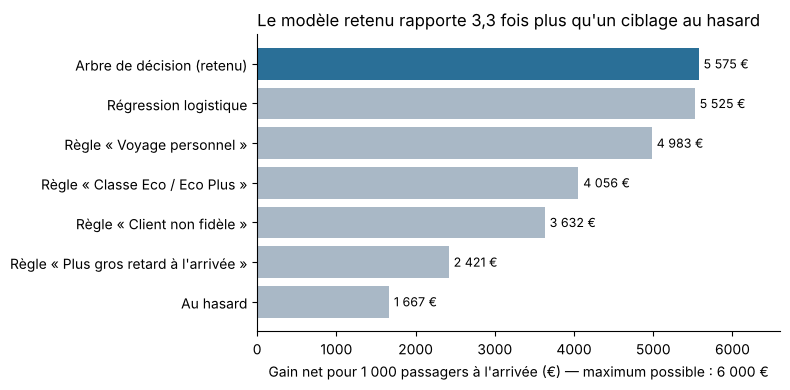

In [5]:
t = methodes.drop("Modèle parfait (borne)").sort_values("Gain / 1000 passagers (€)")
couleurs = ["#2a6f97" if i == retenu else "#a9b8c6" for i in t.index]
etiquettes = [i + " (retenu)" if i == retenu else i for i in t.index]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(etiquettes, t["Gain / 1000 passagers (€)"], color=couleurs)
for k, v in enumerate(t["Gain / 1000 passagers (€)"]):
    ax.text(v + 60, k, f"{v:,.0f} €".replace(",", " "), va="center", fontsize=9)
ax.set_xlim(0, 6600)
ax.set_xlabel("Gain net pour 1 000 passagers à l'arrivée (€) — maximum possible : 6 000 €")
ax.set_title(f"Le modèle retenu rapporte {g[retenu] / g['Au hasard']:.1f} fois plus qu'un ciblage au hasard".replace(".", ","), loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURES / "04b_gain_par_methode.png", dpi=200); plt.show()

## 3. Sensibilité aux hypothèses de la direction

« 1 insatisfait sur 3 ne revient pas » et « l'approche en ramène la moitié » sont des estimations, pas des mesures. On recalcule le gain pour 1 000 passagers (100 approchés) avec des hypothèses plus pessimistes ou plus optimistes.

In [6]:
def gain_1000(precision, p_depart, p_recup):
    v = PERTE_CLIENT * p_depart * p_recup
    return 1000 * config.CAPACITE * (precision * v - config.COUT_APPROCHE)

scenarios = {
    "Optimiste (1/2, 1/2)": (1 / 2, 1 / 2),
    "Hypothèses de la direction (1/3, 1/2)": (1 / 3, 1 / 2),
    "Récupération faible (1/3, 1/4)": (1 / 3, 1 / 4),
    "Pessimiste (1/5, 1/4)": (1 / 5, 1 / 4),
}
p = methodes["Précision top 10 %"]
sens = pd.DataFrame({
    nom: {"Précision minimale": config.COUT_APPROCHE / (PERTE_CLIENT * d * r),
          retenu: gain_1000(p[retenu], d, r),
          "Règle « Voyage personnel »": gain_1000(p["Règle « Voyage personnel »"], d, r),
          "Au hasard": gain_1000(p["Au hasard"], d, r)}
    for nom, (d, r) in scenarios.items()}).T
sens.to_csv(RESULTATS / "04b_sensibilite.csv")
print(f"Le modèle retenu reste rentable tant que (part qui ne revient pas) × (part récupérée) ≥ "
      f"{config.COUT_APPROCHE / (PERTE_CLIENT * p[retenu]):.1%} (direction : {P_DEPART * P_RECUP:.1%})")
sens.style.format({"Précision minimale": "{:.0%}", retenu: "{:,.0f} €",
                   "Règle « Voyage personnel »": "{:,.0f} €", "Au hasard": "{:,.0f} €"})

Le modèle retenu reste rentable tant que (part qui ne revient pas) × (part récupérée) ≥ 7.0% (direction : 16.7%)


,Précision minimale,Arbre de décision,Règle « Voyage personnel »,Au hasard
"Optimiste (1/2, 1/2)",27%,"10,362 €","9,475 €","4,500 €"
"Hypothèses de la direction (1/3, 1/2)",40%,"5,575 €","4,983 €","1,667 €"
"Récupération faible (1/3, 1/4)",80%,787 €,492 €,"-1,167 €"
"Pessimiste (1/5, 1/4)",133%,"-1,128 €","-1,305 €","-2,300 €"


**Lecture :**
- Plus les hypothèses sont pessimistes, plus un ciblage précis compte : avec une récupération faible, le hasard devient perdant, mais le modèle reste rentable et creuse l'écart avec la règle simple.
- Dans le scénario pessimiste, aucune méthode n'est rentable, même un modèle parfait.
- D'où la recommandation d'un **pilote avec groupe témoin** pour mesurer ces deux parts avant de généraliser.